# Principal component analysis

# Jewish populations

- merged_renamed_sds_pca_old.tsv - results of PCA
- jews_and_new_groups.csv - names of samples from Rabbinate cohort, 140 samples

## Upload of files

In [46]:
import pandas as pd
df = pd.read_csv('merged_renamed_sds_pca_old.tsv', sep = '\t')
print('Columns:', df.columns)
print('Number of samples:', df.shape[0])

Columns: Index(['sample_id', 'groups', 'tech', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6',
       'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'PC12', 'PC13', 'PC14', 'PC15',
       'PC16', 'PC17', 'PC18', 'PC19', 'PC20', 'cluster1', 'percent1',
       'cluster2', 'percent2', 'cluster3', 'percent3', 'cluster4', 'percent4',
       'cluster5', 'percent5', 'cluster6', 'percent6', 'cluster7', 'percent7',
       'cluster8', 'percent8', 'cluster9', 'percent9', 'cluster10',
       'percent10', 'cluster11', 'percent11', 'cluster12', 'percent12',
       'cluster13', 'percent13', 'cluster14', 'percent14', 'cluster15',
       'percent15', 'cluster16', 'percent16', 'cluster17', 'percent17',
       'cluster18', 'percent18', 'cluster19', 'percent19', 'cluster20',
       'percent20', 'cluster21', 'percent21', 'cluster22', 'percent22'],
      dtype='object')
Number of samples: 2580


In [47]:
names = pd.read_csv('jews_and_new_groups.csv')
names = names.rename(columns={'IID': 'sample_id', 'groups': 'groups_rab'})
print('Number of samples:', names.shape[0])

Number of samples: 140


## Left merge of PCA results and names of Rabbinate groups

In [50]:
df_merged = df.merge(names, on='sample_id', how='left')

# Edit names of groups
df_merged['cluster1'] = df_merged['cluster1'].str.replace('-', ' ', regex=False)
df_merged['cluster1'] = df_merged['cluster1'].str.replace(',', ', ', regex=False)
df_merged['groups_rab'] = df_merged['groups_rab'].str.replace('_', ' ', regex=False)

# New columns for group names (for )samples of Genotek cohort annotated by cluster1)
df_merged['gr_clusters'] = df_merged['cluster1']

# Exclude of not-studied populations
exclude = ['Armenians, Hemshins', 'Chechens', 'Azerbaijanis, Iranians, Turks, Yazidis', 'Mordvins']
df_merged = df_merged[~df_merged['gr_clusters'].isin(exclude)]

df_merged = df_merged.drop_duplicates(subset=['sample_id'])

# Exclude from Genotek cohort samples already annotated by Rabbinate
df_merged['genot_groups'] = df_merged['gr_clusters']
df_merged.loc[df_merged['groups_rab'].notna(), 'genot_groups'] = pd.NA

# Exclude relative sample from Rabbinate cohort
df_merged = df_merged[df_merged['sample_id'] != 'nx1575']


In [51]:
counts = df_merged['gr_clusters'].value_counts()

print(counts)

gr_clusters
Ashkenazim          2148
Jews Azerbaijani     316
Jews Georgian         74
Jews Uzbekistani      31
Jews Iranian           6
Name: count, dtype: int64


In [52]:
# Genotek cohort
df_merged['genot_groups'].value_counts()

,count
genot_groups,
Ashkenazim,2105
Jews Azerbaijani,267
Jews Georgian,57
Jews Uzbekistani,14
Jews Iranian,4


In [53]:
# Rabbinate cohort
df_merged['groups_rab'].value_counts()

,count
groups_rab,
Mountain Jews,49
Ashkenazi Jews,42
Bukharan Jews,21
Georgian Jews,15
Kurdistani Jews,1


In [54]:
selected_columns = df_merged.columns.str.startswith('PC')

## PC1 PC2

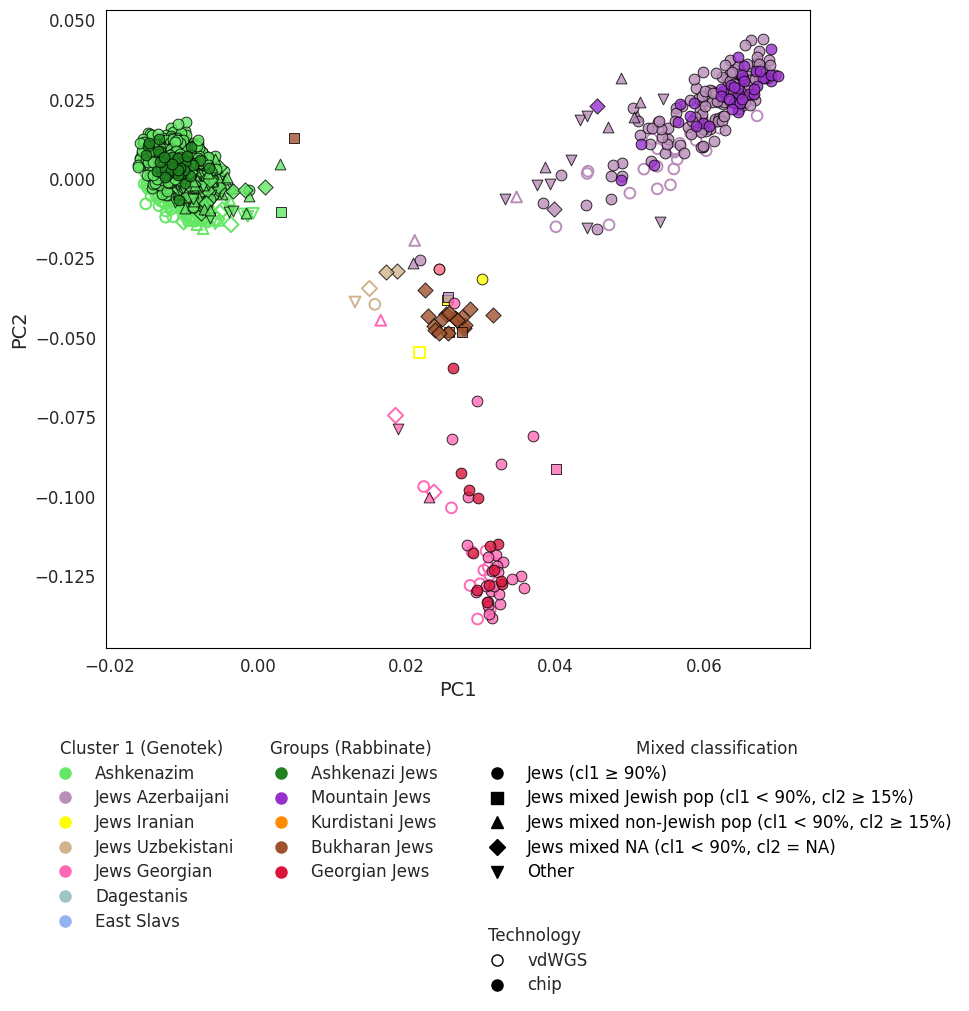

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines

# Reproducibility for the jitter
np.random.seed(42)

# 1. Group by mix of percent1 and percent2 annotation (Mixed classification)
def get_mixed_class(row):
    p1 = row['percent1']
    p2 = row['percent2']
    g_gen = row['genot_groups']
    g_rab = row['groups_rab']
    cl2 = row['cluster2']

    p1 = float(p1) if pd.notna(p1) else np.nan
    p2 = float(p2) if pd.notna(p2) else np.nan

    jewish_gen = {'Ashkenazim', 'Jews Azerbaijani', 'Jews Georgian',
                  'Jews Iranian', 'Jews Uzbekistani'}
    jewish_rab = {'Ashkenazi Jews', 'Mountain Jews', 'Kurdistani Jews',
                  'Bukharan Jews', 'Georgian Jews'}

    is_jewish = (pd.notna(g_gen) and g_gen in jewish_gen) or \
                (pd.notna(g_rab) and g_rab in jewish_rab)

    # 1: percent1 >= 90% and population is Jewish
    if pd.notna(p1) and p1 >= 90 and is_jewish:
        return 'Jews (cl1 ≥ 90%)'

    # 2: percent1 < 90% and percent2 = NA
    if pd.notna(p1) and p1 < 90 and pd.isna(p2) and is_jewish:
        return 'Jews mixed NA (cl1 < 90%, cl2 = NA)'

    # 3: percent1 < 90% and percent2 >= 15%
    if is_jewish and (pd.notna(p1) and p1 < 90 and pd.notna(p2) and p2 >= 15):
        # FIX: guard against non-string cl2
        if isinstance(cl2, str) and 'Jew' in cl2:
            return 'Jews mixed Jewish pop (cl1 < 90%, cl2 ≥ 15%)'
        else:
            return 'Jews mixed non-Jewish pop (cl1 < 90%, cl2 ≥ 15%)'

    return 'Other'

df_merged['mixed_classification'] = df_merged.apply(get_mixed_class, axis=1)


# 2. Colors
color_map = {
    'Ashkenazim': '#64e764',
    'Ashkenazi Jews': '#1f821f',
    'Jews Azerbaijani': '#ba8eba',
    'Jews Iranian': '#ffff00',
    'Jews Uzbekistani': '#d2b48c',
    'Jews Georgian': '#ff69b4',
    'Dagestanis': '#9fc4c6',
    'East Slavs': '#92b4f2',
    'Mountain Jews': '#9831cb',
    'Kurdistani Jews': '#ff8c00',
    'Bukharan Jews': '#a0522d',
    'Georgian Jews': '#dc143c'
}

# FIX: label must match get_mixed_class output exactly ('≥' not '>')
marker_map = {
    'Jews (cl1 ≥ 90%)': 'o',
    'Jews mixed Jewish pop (cl1 < 90%, cl2 ≥ 15%)': 's',
    'Jews mixed non-Jewish pop (cl1 < 90%, cl2 ≥ 15%)': '^',
    'Jews mixed NA (cl1 < 90%, cl2 = NA)': 'D',
    'Other': 'v'
}

# 3. PCA plot
sns.set_style("white")
fig, ax = plt.subplots(figsize=(8, 11))

def plot_points(df):
    for _, row in df.iterrows():
        color = color_map.get(row['genot_groups'])
        if color is None:
            color = color_map.get(row['groups_rab'], 'gray')

        m_class = row.get('mixed_classification', 'Other')
        marker = marker_map.get(m_class, 'x')

        tech = row['tech']

        jitter_x = np.random.normal(0, 0.0005)
        jitter_y = np.random.normal(0, 0.0005)

        has_g_rab = pd.notna(row['groups_rab'])

        if tech == 'chip':
            face_c = color
            edge_c = 'black'
            line_w = 0.7
            alpha_val = 0.8
            base_zord = 3 if has_g_rab else 1
        else:
            face_c = 'none'
            edge_c = color
            line_w = 1.4
            alpha_val = 1.0
            base_zord = 2 if has_g_rab else 0

        ax.scatter(
            row['PC1'] + jitter_x,
            row['PC2'] + jitter_y,
            c=face_c,
            edgecolors=edge_c,
            marker=marker,
            s=60,
            linewidths=line_w,
            alpha=alpha_val,
            zorder=base_zord
        )

plot_points(df_merged)

ax.set_xlabel('PC1', fontsize=14)
ax.set_ylabel('PC2', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=12)
#ax.set_title('PCA of Merged Data', fontsize=14)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_color('black')

# 4. Legend handles
genot_keys = ['Ashkenazim', 'Jews Azerbaijani', 'Jews Iranian', 'Jews Uzbekistani',
              'Jews Georgian', 'Dagestanis', 'East Slavs']
color_handles = [mlines.Line2D([], [], color=color_map.get(k, 'gray'), marker='o',
                               linestyle='None', markersize=8, label=k) for k in genot_keys]

rab_keys = ['Ashkenazi Jews', 'Mountain Jews', 'Kurdistani Jews', 'Bukharan Jews', 'Georgian Jews']
rab_handles = [mlines.Line2D([], [], color=color_map.get(k, 'gray'), marker='o',
                             linestyle='None', markersize=8, label=k) for k in rab_keys]

mixed_handles = [mlines.Line2D([], [], color='black', marker=marker, linestyle='None',
                               markersize=8, markeredgecolor='black',
                               markerfacecolor='black', label=label)
                 for label, marker in marker_map.items()]

tech_handles = [
    mlines.Line2D([], [], color='black', marker='o', linestyle='None', markersize=8,
                  markeredgecolor='black', markerfacecolor='none', label='vdWGS'),
    mlines.Line2D([], [], color='black', marker='o', linestyle='None', markersize=8,
                  markeredgecolor='black', markerfacecolor='black', label='chip')
]

# 5. Legends below PCA
fig.subplots_adjust(left=0.10, right=0.98, top=0.92, bottom=0.34)

leg1 = fig.legend(handles=color_handles, title='Cluster 1 (Genotek)',
                  loc='upper left', bbox_to_anchor=(0.01, 0.27),
                  fontsize=12, title_fontsize=12, frameon=False, labelspacing=0.4)

leg2 = fig.legend(handles=rab_handles, title='Groups (Rabbinate)',
                  loc='upper left', bbox_to_anchor=(0.28, 0.27),
                  fontsize=12, title_fontsize=12, frameon=False, labelspacing=0.4)

leg3 = fig.legend(handles=mixed_handles, title='Mixed classification',
                  loc='upper left', bbox_to_anchor=(0.55, 0.27),
                  fontsize=12, labelcolor='black', title_fontsize=12,
                  frameon=False, labelspacing=0.4)

leg4 = fig.legend(handles=tech_handles, title='Technology',
                  loc='upper left', bbox_to_anchor=(0.55, 0.1),
                  fontsize=12, title_fontsize=12, frameon=False, labelspacing=0.4)

# 6. Save
fig.savefig('PCA_J_PC1_PC2.png', dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig('PCA_J_PC1_PC2.pdf', bbox_inches='tight', facecolor='white')

plt.show()

## PC2 PC3

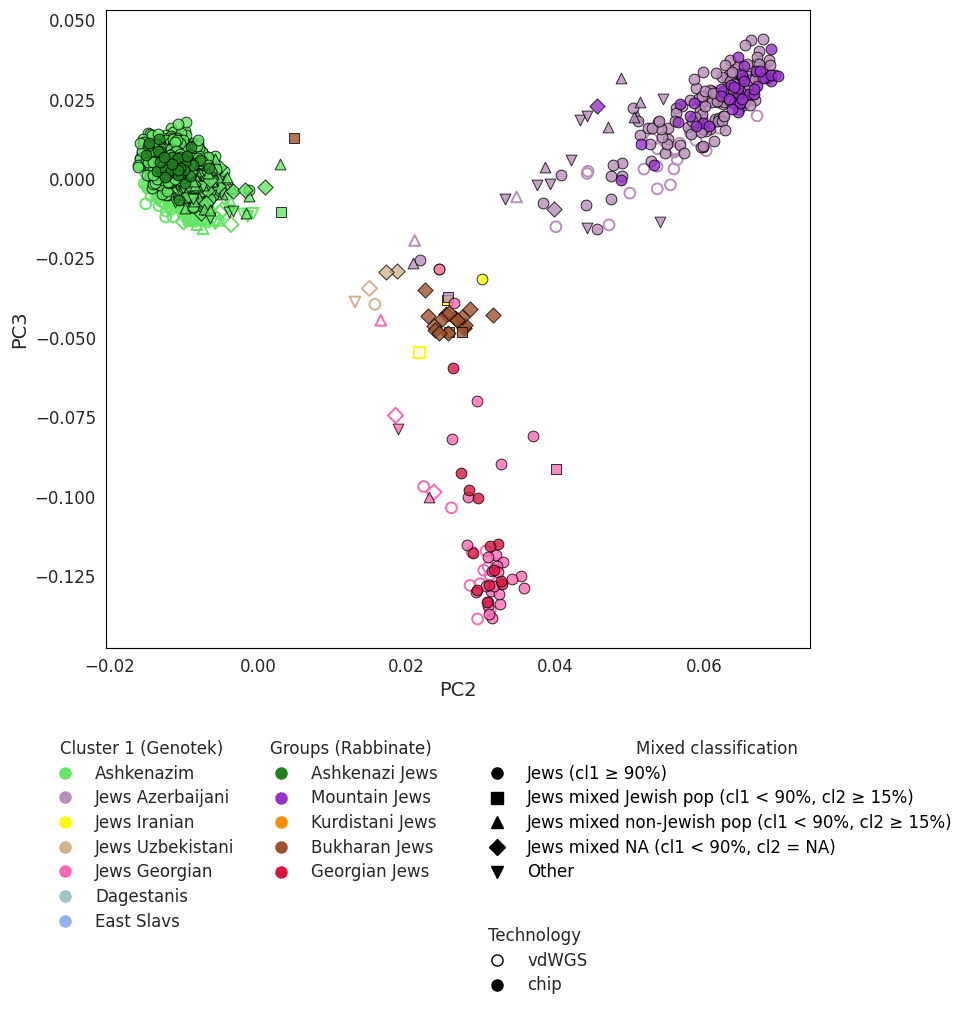

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines

# Reproducibility for the jitter
np.random.seed(42)

# 1. Group by mix of percent1 and percent2 annotation (Mixed classification)
df_merged['mixed_classification'] = df_merged.apply(get_mixed_class, axis=1)


# 2. Colors
color_map = {
    'Ashkenazim': '#64e764',
    'Ashkenazi Jews': '#1f821f',
    'Jews Azerbaijani': '#ba8eba',
    'Jews Iranian': '#ffff00',
    'Jews Uzbekistani': '#d2b48c',
    'Jews Georgian': '#ff69b4',
    'Dagestanis': '#9fc4c6',
    'East Slavs': '#92b4f2',
    'Mountain Jews': '#9831cb',
    'Kurdistani Jews': '#ff8c00',
    'Bukharan Jews': '#a0522d',
    'Georgian Jews': '#dc143c'
}

# FIX: label must match get_mixed_class output exactly ('≥' not '>')
marker_map = {
    'Jews (cl1 ≥ 90%)': 'o',
    'Jews mixed Jewish pop (cl1 < 90%, cl2 ≥ 15%)': 's',
    'Jews mixed non-Jewish pop (cl1 < 90%, cl2 ≥ 15%)': '^',
    'Jews mixed NA (cl1 < 90%, cl2 = NA)': 'D',
    'Other': 'v'
}

# 3. PCA plot
sns.set_style("white")
fig, ax = plt.subplots(figsize=(8, 11))

plot_points(df_merged)

ax.set_xlabel('PC2', fontsize=14)
ax.set_ylabel('PC3', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=12)
#ax.set_title('PCA of Merged Data', fontsize=14)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_color('black')

# 4. Legend handles
genot_keys = ['Ashkenazim', 'Jews Azerbaijani', 'Jews Iranian', 'Jews Uzbekistani',
              'Jews Georgian', 'Dagestanis', 'East Slavs']
color_handles = [mlines.Line2D([], [], color=color_map.get(k, 'gray'), marker='o',
                               linestyle='None', markersize=8, label=k) for k in genot_keys]

rab_keys = ['Ashkenazi Jews', 'Mountain Jews', 'Kurdistani Jews', 'Bukharan Jews', 'Georgian Jews']
rab_handles = [mlines.Line2D([], [], color=color_map.get(k, 'gray'), marker='o',
                             linestyle='None', markersize=8, label=k) for k in rab_keys]

mixed_handles = [mlines.Line2D([], [], color='black', marker=marker, linestyle='None',
                               markersize=8, markeredgecolor='black',
                               markerfacecolor='black', label=label)
                 for label, marker in marker_map.items()]

tech_handles = [
    mlines.Line2D([], [], color='black', marker='o', linestyle='None', markersize=8,
                  markeredgecolor='black', markerfacecolor='none', label='vdWGS'),
    mlines.Line2D([], [], color='black', marker='o', linestyle='None', markersize=8,
                  markeredgecolor='black', markerfacecolor='black', label='chip')
]

# 5. Legends below PCA
fig.subplots_adjust(left=0.10, right=0.98, top=0.92, bottom=0.34)

leg1 = fig.legend(handles=color_handles, title='Cluster 1 (Genotek)',
                  loc='upper left', bbox_to_anchor=(0.01, 0.27),
                  fontsize=12, title_fontsize=12, frameon=False, labelspacing=0.4)

leg2 = fig.legend(handles=rab_handles, title='Groups (Rabbinate)',
                  loc='upper left', bbox_to_anchor=(0.28, 0.27),
                  fontsize=12, title_fontsize=12, frameon=False, labelspacing=0.4)

leg3 = fig.legend(handles=mixed_handles, title='Mixed classification',
                  loc='upper left', bbox_to_anchor=(0.55, 0.27),
                  fontsize=12, labelcolor='black', title_fontsize=12,
                  frameon=False, labelspacing=0.4)

leg4 = fig.legend(handles=tech_handles, title='Technology',
                  loc='upper left', bbox_to_anchor=(0.55, 0.1),
                  fontsize=12, title_fontsize=12, frameon=False, labelspacing=0.4)

# 6. Save
fig.savefig('PCA_J_PC2_PC3.png', dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig('PCA_J_PC2_PC3.pdf', bbox_inches='tight', facecolor='white')

plt.show()

# Jewish and non-Jewish populations (East Slavs, Dagestanis)

Files:
- merged_renamed_pca_fin_dag_sl.tsv - results of PCA , 2802 samples with anonymized samples'ID (columns: 'sample_id', 'groups', 'tech', 'chip_type', 'batch', 'PC1', 'PC2',
       'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'PC12',
       'PC13', 'PC14', 'PC15', 'PC16', 'PC17', 'PC18', 'PC19', 'PC20',
       'cluster1', 'percent1', 'cluster2', 'percent2', 'cluster3', 'percent3',
       'cluster4', 'percent4', 'cluster5', 'percent5', 'cluster6', 'percent6',
       'cluster7', 'percent7', 'icd10Diseases', 'y_hap_apex', 'y_hap_long',
       'y_hap_short', 'mito_hap_apex', 'mito_hap_long', 'mito_hap_short')
- jews_and_new_groups.csv - names of samples from Rabbinate cohort, 140 samples

## Upload of files

In [8]:
import pandas as pd
df = pd.read_csv('merged_renamed_pca_fin_dag_sl.tsv', sep = '\t')
print('Columns:', df.columns)
print('Number of samples:', df.shape[0])

Columns: Index(['sample_id', 'groups', 'tech', 'chip_type', 'batch', 'PC1', 'PC2',
       'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'PC12',
       'PC13', 'PC14', 'PC15', 'PC16', 'PC17', 'PC18', 'PC19', 'PC20',
       'cluster1', 'percent1', 'cluster2', 'percent2', 'cluster3', 'percent3',
       'cluster4', 'percent4', 'cluster5', 'percent5', 'cluster6', 'percent6',
       'cluster7', 'percent7', 'icd10Diseases', 'y_hap_apex', 'y_hap_long',
       'y_hap_short', 'mito_hap_apex', 'mito_hap_long', 'mito_hap_short'],
      dtype='object')
Number of samples: 2802


In [10]:
names = pd.read_csv('jews_and_new_groups.csv')
names = names.rename(columns={'IID': 'sample_id', 'groups': 'groups_rab'})
print('Number of samples:', names.shape[0])

Number of samples: 140


## Left merge of PCA results and names of Rabbinate groups

In [14]:
df_merged = df.merge(names, on='sample_id', how='left')
df_merged.columns

Index(['sample_id', 'groups', 'tech', 'chip_type', 'batch', 'PC1', 'PC2',
       'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'PC12',
       'PC13', 'PC14', 'PC15', 'PC16', 'PC17', 'PC18', 'PC19', 'PC20',
       'cluster1', 'percent1', 'cluster2', 'percent2', 'cluster3', 'percent3',
       'cluster4', 'percent4', 'cluster5', 'percent5', 'cluster6', 'percent6',
       'cluster7', 'percent7', 'icd10Diseases', 'y_hap_apex', 'y_hap_long',
       'y_hap_short', 'mito_hap_apex', 'mito_hap_long', 'mito_hap_short',
       'groups_rab'],
      dtype='object')

In [15]:
# Edit names of groups
df_merged['cluster1'] = df_merged['cluster1'].str.replace('-', ' ', regex=False)
df_merged['cluster1'] = df_merged['cluster1'].str.replace(',', ', ', regex=False)
df_merged['groups_rab'] = df_merged['groups_rab'].str.replace('_', ' ', regex=False)

In [16]:
# New columns for group names (for )samples of Genotek cohort annotated by cluster1)
df_merged['gr_clusters'] = df_merged['cluster1']

# Combine populations to East Slavs
df_merged.loc[df_merged['cluster1'] == 'Russians', 'gr_clusters'] = 'East Slavs'
df_merged.loc[df_merged['cluster1'] == 'Ukrainians', 'gr_clusters'] = 'East Slavs'
df_merged.loc[df_merged['cluster1'] == 'Belarusians', 'gr_clusters'] = 'East Slavs'
df_merged.loc[df_merged['cluster1'] == 'Southern Russians', 'gr_clusters'] = 'East Slavs'
df_merged.loc[df_merged['cluster1'] == 'Northern Russians', 'gr_clusters'] = 'East Slavs'
df_merged.loc[df_merged['cluster1'] == 'Dagestan', 'gr_clusters'] = 'Dagestanis'

# Exclude of not-studied populations
exclude = ['Armenians, Hemshins', 'Chechens', 'Azerbaijanis, Iranians, Turks, Yazidis', 'Mordvins']
df_merged = df_merged[~df_merged['gr_clusters'].isin(exclude)]

df_merged = df_merged.drop_duplicates(subset=['sample_id'])

In [17]:
counts = df_merged['gr_clusters'].value_counts()

print(counts)

gr_clusters
Ashkenazim          1730
East Slavs           426
Jews Azerbaijani     247
Dagestanis           221
Jews Georgian         62
Jews Uzbekistani      23
Jews Iranian           4
Name: count, dtype: int64


In [18]:
# Exclude from Genotek cohort samples already annotated by Rabbinate
df_merged['genot_groups'] = df_merged['gr_clusters']
df_merged.loc[df_merged['groups_rab'].notna(), 'genot_groups'] = pd.NA

In [20]:
# Genotek cohort
df_merged['genot_groups'].value_counts()

,count
genot_groups,
Ashkenazim,1687
East Slavs,425
Dagestanis,221
Jews Azerbaijani,198
Jews Georgian,45
Jews Uzbekistani,6
Jews Iranian,2


In [19]:
# Rabbinate cohort
df_merged['groups_rab'].value_counts()

,count
groups_rab,
Mountain Jews,49
Ashkenazi Jews,42
Bukharan Jews,22
Georgian Jews,16
Kurdistani Jews,10


In [25]:
# Exclude relative sample from Rabbinate cohort
df_merged = df_merged[df_merged['sample_id'] != 'nx1575']

In [109]:
selected_columns = df_merged.columns.str.startswith('PC')

In [114]:
[set(df_merged['genot_groups'])]

[{<NA>,
  'Ashkenazim',
  'Dagestanis',
  'East Slavs',
  'Jews Azerbaijani',
  'Jews Georgian',
  'Jews Iranian',
  'Jews Uzbekistani'}]

In [26]:
[set(df_merged['groups_rab'])]

[{'Ashkenazi Jews',
  'Bukharan Jews',
  'Georgian Jews',
  'Kurdistani Jews',
  'Mountain Jews',
  nan}]

## PC1 PC2

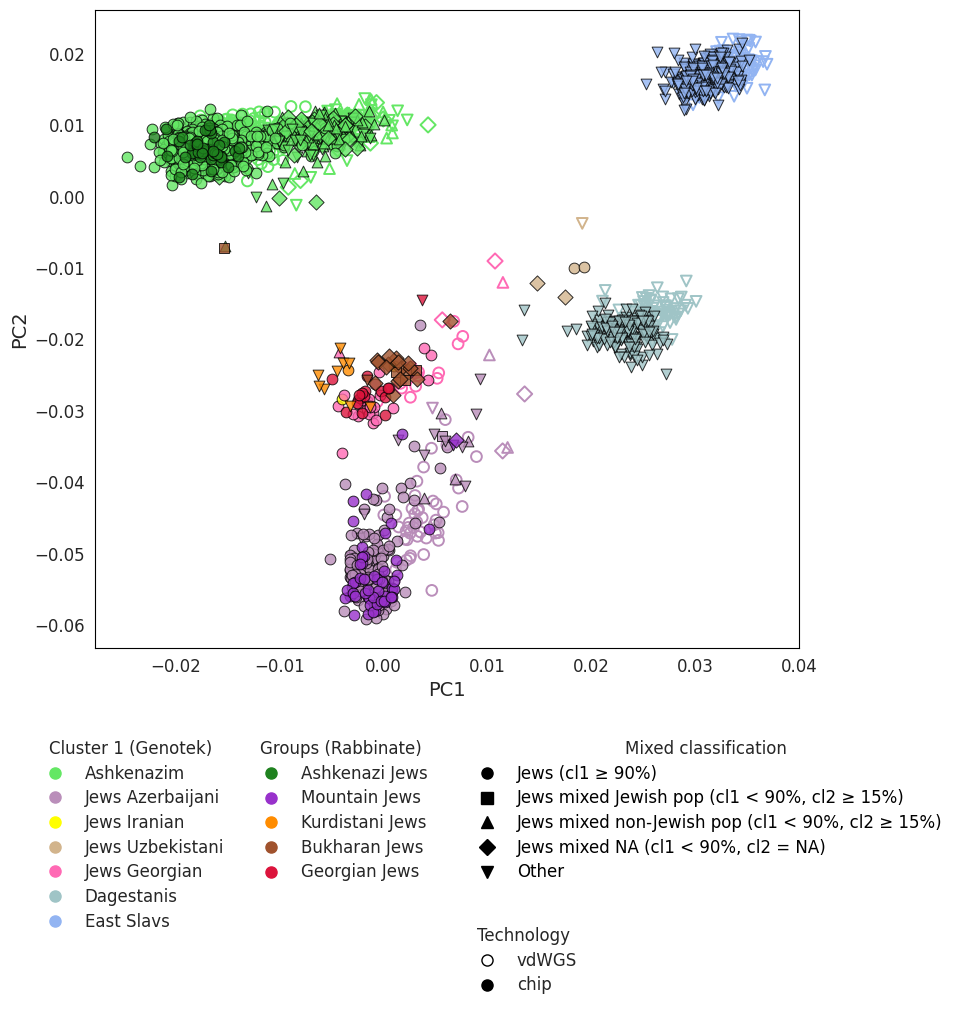

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines

# Reproducibility for the jitter
np.random.seed(42)

# 1. Group by mix of percent1 and percent2 annotation (Mixed classification)
def get_mixed_class(row):
    p1 = row['percent1']
    p2 = row['percent2']
    g_gen = row['genot_groups']
    g_rab = row['groups_rab']
    cl2 = row['cluster2']

    p1 = float(p1) if pd.notna(p1) else np.nan
    p2 = float(p2) if pd.notna(p2) else np.nan

    jewish_gen = {'Ashkenazim', 'Jews Azerbaijani', 'Jews Georgian',
                  'Jews Iranian', 'Jews Uzbekistani'}
    jewish_rab = {'Ashkenazi Jews', 'Mountain Jews', 'Kurdistani Jews',
                  'Bukharan Jews', 'Georgian Jews'}

    is_jewish = (pd.notna(g_gen) and g_gen in jewish_gen) or \
                (pd.notna(g_rab) and g_rab in jewish_rab)

    # 1: percent1 >= 90% and population is Jewish
    if pd.notna(p1) and p1 >= 90 and is_jewish:
        return 'Jews (cl1 ≥ 90%)'

    # 2: percent1 < 90% and percent2 = NA
    if pd.notna(p1) and p1 < 90 and pd.isna(p2) and is_jewish:
        return 'Jews mixed NA (cl1 < 90%, cl2 = NA)'

    # 3: percent1 < 90% and percent2 >= 15%
    if is_jewish and (pd.notna(p1) and p1 < 90 and pd.notna(p2) and p2 >= 15):
        # FIX: guard against non-string cl2
        if isinstance(cl2, str) and 'Jew' in cl2:
            return 'Jews mixed Jewish pop (cl1 < 90%, cl2 ≥ 15%)'
        else:
            return 'Jews mixed non-Jewish pop (cl1 < 90%, cl2 ≥ 15%)'

    return 'Other'

df_merged['mixed_classification'] = df_merged.apply(get_mixed_class, axis=1)


# 2. Colors
color_map = {
    'Ashkenazim': '#64e764',
    'Ashkenazi Jews': '#1f821f',
    'Jews Azerbaijani': '#ba8eba',
    'Jews Iranian': '#ffff00',
    'Jews Uzbekistani': '#d2b48c',
    'Jews Georgian': '#ff69b4',
    'Dagestanis': '#9fc4c6',
    'East Slavs': '#92b4f2',
    'Mountain Jews': '#9831cb',
    'Kurdistani Jews': '#ff8c00',
    'Bukharan Jews': '#a0522d',
    'Georgian Jews': '#dc143c'
}

# FIX: label must match get_mixed_class output exactly ('≥' not '>')
marker_map = {
    'Jews (cl1 ≥ 90%)': 'o',
    'Jews mixed Jewish pop (cl1 < 90%, cl2 ≥ 15%)': 's',
    'Jews mixed non-Jewish pop (cl1 < 90%, cl2 ≥ 15%)': '^',
    'Jews mixed NA (cl1 < 90%, cl2 = NA)': 'D',
    'Other': 'v'
}

# 3. PCA plot
sns.set_style("white")
fig, ax = plt.subplots(figsize=(8, 11))

def plot_points(df):
    for _, row in df.iterrows():
        color = color_map.get(row['genot_groups'])
        if color is None:
            color = color_map.get(row['groups_rab'], 'gray')

        m_class = row.get('mixed_classification', 'Other')
        marker = marker_map.get(m_class, 'x')

        tech = row['tech']

        jitter_x = np.random.normal(0, 0.0005)
        jitter_y = np.random.normal(0, 0.0005)

        has_g_rab = pd.notna(row['groups_rab'])

        if tech == 'chip':
            face_c = color
            edge_c = 'black'
            line_w = 0.7
            alpha_val = 0.8
            base_zord = 3 if has_g_rab else 1
        else:
            face_c = 'none'
            edge_c = color
            line_w = 1.4
            alpha_val = 1.0
            base_zord = 2 if has_g_rab else 0

        ax.scatter(
            row['PC1'] + jitter_x,
            row['PC2'] + jitter_y,
            c=face_c,
            edgecolors=edge_c,
            marker=marker,
            s=60,
            linewidths=line_w,
            alpha=alpha_val,
            zorder=base_zord
        )

plot_points(df_merged)

ax.set_xlabel('PC1', fontsize=14)
ax.set_ylabel('PC2', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=12)
#ax.set_title('PCA of Merged Data', fontsize=14)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_color('black')

# 4. Legend handles
genot_keys = ['Ashkenazim', 'Jews Azerbaijani', 'Jews Iranian', 'Jews Uzbekistani',
              'Jews Georgian', 'Dagestanis', 'East Slavs']
color_handles = [mlines.Line2D([], [], color=color_map.get(k, 'gray'), marker='o',
                               linestyle='None', markersize=8, label=k) for k in genot_keys]

rab_keys = ['Ashkenazi Jews', 'Mountain Jews', 'Kurdistani Jews', 'Bukharan Jews', 'Georgian Jews']
rab_handles = [mlines.Line2D([], [], color=color_map.get(k, 'gray'), marker='o',
                             linestyle='None', markersize=8, label=k) for k in rab_keys]

mixed_handles = [mlines.Line2D([], [], color='black', marker=marker, linestyle='None',
                               markersize=8, markeredgecolor='black',
                               markerfacecolor='black', label=label)
                 for label, marker in marker_map.items()]

tech_handles = [
    mlines.Line2D([], [], color='black', marker='o', linestyle='None', markersize=8,
                  markeredgecolor='black', markerfacecolor='none', label='vdWGS'),
    mlines.Line2D([], [], color='black', marker='o', linestyle='None', markersize=8,
                  markeredgecolor='black', markerfacecolor='black', label='chip')
]

# 5. Legends below PCA
fig.subplots_adjust(left=0.10, right=0.98, top=0.92, bottom=0.34)

leg1 = fig.legend(handles=color_handles, title='Cluster 1 (Genotek)',
                  loc='upper left', bbox_to_anchor=(0.01, 0.27),
                  fontsize=12, title_fontsize=12, frameon=False, labelspacing=0.4)

leg2 = fig.legend(handles=rab_handles, title='Groups (Rabbinate)',
                  loc='upper left', bbox_to_anchor=(0.28, 0.27),
                  fontsize=12, title_fontsize=12, frameon=False, labelspacing=0.4)

leg3 = fig.legend(handles=mixed_handles, title='Mixed classification',
                  loc='upper left', bbox_to_anchor=(0.55, 0.27),
                  fontsize=12, labelcolor='black', title_fontsize=12,
                  frameon=False, labelspacing=0.4)

leg4 = fig.legend(handles=tech_handles, title='Technology',
                  loc='upper left', bbox_to_anchor=(0.55, 0.1),
                  fontsize=12, title_fontsize=12, frameon=False, labelspacing=0.4)

# 6. Save
fig.savefig('PCA_PC1_PC2.png', dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig('PCA_PC1_PC2.pdf', bbox_inches='tight', facecolor='white')

plt.show()

## PC2 PC3

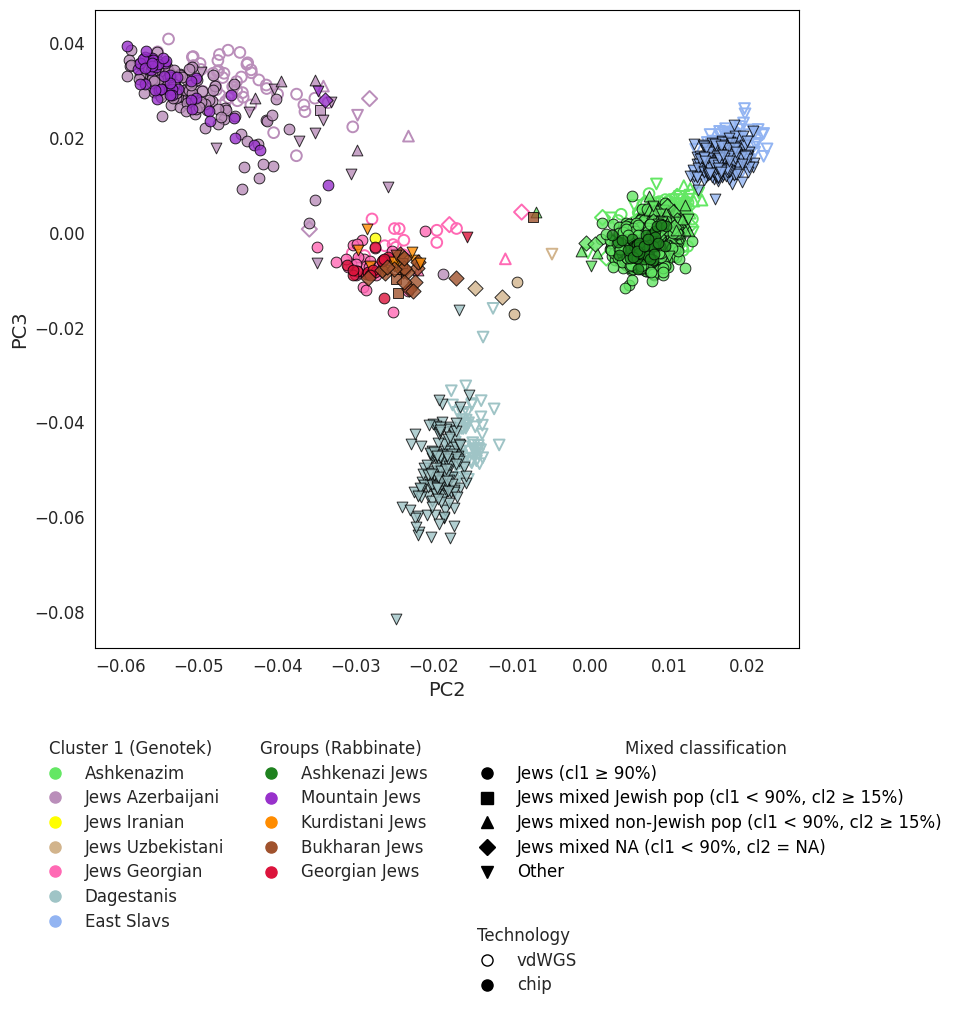

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines

# Reproducibility for the jitter
np.random.seed(42)

# 1. Group by mix of percent1 and percent2 annotation (Mixed classification)
df_merged['mixed_classification'] = df_merged.apply(get_mixed_class, axis=1)


# 2. Colors
color_map = {
    'Ashkenazim': '#64e764',
    'Ashkenazi Jews': '#1f821f',
    'Jews Azerbaijani': '#ba8eba',
    'Jews Iranian': '#ffff00',
    'Jews Uzbekistani': '#d2b48c',
    'Jews Georgian': '#ff69b4',
    'Dagestanis': '#9fc4c6',
    'East Slavs': '#92b4f2',
    'Mountain Jews': '#9831cb',
    'Kurdistani Jews': '#ff8c00',
    'Bukharan Jews': '#a0522d',
    'Georgian Jews': '#dc143c'
}

# FIX: label must match get_mixed_class output exactly ('≥' not '>')
marker_map = {
    'Jews (cl1 ≥ 90%)': 'o',
    'Jews mixed Jewish pop (cl1 < 90%, cl2 ≥ 15%)': 's',
    'Jews mixed non-Jewish pop (cl1 < 90%, cl2 ≥ 15%)': '^',
    'Jews mixed NA (cl1 < 90%, cl2 = NA)': 'D',
    'Other': 'v'
}

# 3. PCA plot
sns.set_style("white")
fig, ax = plt.subplots(figsize=(8, 11))
plot_points(df_merged)

ax.set_xlabel('PC2', fontsize=14)
ax.set_ylabel('PC3', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=12)
#ax.set_title('PCA of Merged Data', fontsize=14)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_color('black')

# 4. Legend handles
genot_keys = ['Ashkenazim', 'Jews Azerbaijani', 'Jews Iranian', 'Jews Uzbekistani',
              'Jews Georgian', 'Dagestanis', 'East Slavs']
color_handles = [mlines.Line2D([], [], color=color_map.get(k, 'gray'), marker='o',
                               linestyle='None', markersize=8, label=k) for k in genot_keys]

rab_keys = ['Ashkenazi Jews', 'Mountain Jews', 'Kurdistani Jews', 'Bukharan Jews', 'Georgian Jews']
rab_handles = [mlines.Line2D([], [], color=color_map.get(k, 'gray'), marker='o',
                             linestyle='None', markersize=8, label=k) for k in rab_keys]

mixed_handles = [mlines.Line2D([], [], color='black', marker=marker, linestyle='None',
                               markersize=8, markeredgecolor='black',
                               markerfacecolor='black', label=label)
                 for label, marker in marker_map.items()]

tech_handles = [
    mlines.Line2D([], [], color='black', marker='o', linestyle='None', markersize=8,
                  markeredgecolor='black', markerfacecolor='none', label='vdWGS'),
    mlines.Line2D([], [], color='black', marker='o', linestyle='None', markersize=8,
                  markeredgecolor='black', markerfacecolor='black', label='chip')
]

# 5. Legends below PCA
fig.subplots_adjust(left=0.10, right=0.98, top=0.92, bottom=0.34)

leg1 = fig.legend(handles=color_handles, title='Cluster 1 (Genotek)',
                  loc='upper left', bbox_to_anchor=(0.01, 0.27),
                  fontsize=12, title_fontsize=12, frameon=False, labelspacing=0.4)

leg2 = fig.legend(handles=rab_handles, title='Groups (Rabbinate)',
                  loc='upper left', bbox_to_anchor=(0.28, 0.27),
                  fontsize=12, title_fontsize=12, frameon=False, labelspacing=0.4)

leg3 = fig.legend(handles=mixed_handles, title='Mixed classification',
                  loc='upper left', bbox_to_anchor=(0.55, 0.27),
                  fontsize=12, labelcolor='black', title_fontsize=12,
                  frameon=False, labelspacing=0.4)

leg4 = fig.legend(handles=tech_handles, title='Technology',
                  loc='upper left', bbox_to_anchor=(0.55, 0.1),
                  fontsize=12, title_fontsize=12, frameon=False, labelspacing=0.4)

# 6. Save
fig.savefig('PCA_PC2_PC3.png', dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig('PCA_PC2_PC3.pdf', bbox_inches='tight', facecolor='white')

plt.show()

In [144]:
# Specimen mapped with Ashkenazi
df_merged[df_merged['sample_id'] == 'tq8153']

,sample_id,groups,tech,chip_type,batch,PC1,PC2,PC3,PC4,PC5,...,y_hap_apex,y_hap_long,y_hap_short,mito_hap_apex,mito_hap_long,mito_hap_short,groups_rab,gr_clusters,genot_groups,mixed_classification
1606,tq8153,Bukharan_Jews,chip,gsa3,2021-08-23,-0.014849,-0.006851,0.003747,-0.005754,0.004682,...,NaN,NaN,NaN,NaN,NaN,NaN,Bukharan Jews,Ashkenazim,<NA>,"Mixed Jews (cl1 < 90%, cl2 > 15%)"
